# 03 — Resultados dos 6 experimentos

Lê apenas os arquivos salvos em `results/experimentos/<experimento>/` (nenhum treino é feito aqui).
Gera as tabelas em `results/tables/` e as figuras em `results/figures/`.

Protocolo: treino ajusta, **F1 macro de validação escolhe**, teste é usado só no fim, sem reajuste.

In [1]:
import json, sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.config import CLASSES, DATA_DIR, EXPERIMENTOS, RESULTS_DIR, RESULTS_EXP_DIR
from src.dataset import encontrar_raiz
from src.report import carregar_experimento, concluidos, tabela_resumo
from src.viz import AZUL, LARANJA, VERDE_AGUA, TEXTO, TEXTO_2, aplicar_estilo, salvar

aplicar_estilo()
pd.set_option("display.precision", 3)
TAB_DIR = RESULTS_DIR / "tables"; TAB_DIR.mkdir(parents=True, exist_ok=True)

NOMES = {
    "exp1_mlp_128x96": "1 · MLP 128×96",
    "exp2_mlp_128x96_pesos": "2 · MLP 128×96 + pesos",
    "exp3_cnn_128x96": "3 · CNN 128×96",
    "exp4_cnn_128x96_pesos": "4 · CNN 128×96 + pesos",
    "exp5_cnn_256x192": "5 · CNN 256×192",
    "exp6_cnn_512x384": "6 · CNN 512×384",
}
EXPS = [e for e in EXPERIMENTOS if e in concluidos(RESULTS_EXP_DIR)]
R = {e: carregar_experimento(e, RESULTS_EXP_DIR) for e in EXPS}
print("Experimentos encontrados:", len(EXPS), "de", len(EXPERIMENTOS))
print("Hardware:", {R[e]["config"]["hardware"]["nome"] for e in EXPS})
print("Versões:", R[EXPS[0]]["config"]["versoes"])

Experimentos encontrados: 6 de 6
Hardware: {'Tesla T4'}
Versões: {'python': '3.13.16', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}


## 1. Métricas e custo dos 6 experimentos

In [2]:
resumo = tabela_resumo(RESULTS_EXP_DIR)
resumo.index = [NOMES[e] for e in resumo.index]
metr = resumo[["f1_macro_val", "acuracia_teste", "f1_macro_teste"]].rename(columns={
    "f1_macro_val": "F1 macro (val)", "acuracia_teste": "Acurácia (teste)", "f1_macro_teste": "F1 macro (teste)"})
metr.round(3).to_csv(TAB_DIR / "tabela_metricas.csv")
melhor_exp = tabela_resumo(RESULTS_EXP_DIR)["f1_macro_val"].idxmax()
print("Maior F1 macro de validação (modelo selecionado):", NOMES[melhor_exp])
metr.style.format("{:.3f}").highlight_max(subset=["F1 macro (val)"], color="#cde2fb")

Maior F1 macro de validação (modelo selecionado): 2 · MLP 128×96 + pesos


,F1 macro (val),Acurácia (teste),F1 macro (teste)
1 · MLP 128×96,0.551,0.537,0.506
2 · MLP 128×96 + pesos,0.560,0.550,0.535
3 · CNN 128×96,0.528,0.553,0.509
4 · CNN 128×96 + pesos,0.523,0.484,0.463
5 · CNN 256×192,0.541,0.529,0.511
6 · CNN 512×384,0.541,0.597,0.537


In [3]:
custo = resumo[["parametros", "tamanho_mb", "epocas", "epoca_restaurada", "tempo_total_s",
                "tempo_epoca_s", "pico_vram_mb", "pico_ram_mb", "lote", "hardware"]].rename(columns={
    "parametros": "Parâmetros", "tamanho_mb": "Modelo (MB)", "epocas": "Épocas", "epoca_restaurada": "Época salva",
    "tempo_total_s": "Tempo total (s)", "tempo_epoca_s": "Tempo/época (s)", "pico_vram_mb": "Pico VRAM (MB)",
    "pico_ram_mb": "Pico RAM (MB)", "lote": "Lote", "hardware": "Hardware"})
custo.round(2).to_csv(TAB_DIR / "tabela_custo.csv")
print("Método de medição:", R[EXPS[0]]["cost"]["metodo_medicao"])
custo.style.format({"Parâmetros": "{:,.0f}", "Modelo (MB)": "{:.2f}", "Tempo total (s)": "{:.1f}",
                    "Tempo/época (s)": "{:.2f}", "Pico VRAM (MB)": "{:.0f}", "Pico RAM (MB)": "{:.0f}"}, na_rep="—")

Método de medição: time.perf_counter em volta de model.fit (sem download, descompactacao e leitura das imagens, feitos antes); tempo por epoca via callback; pico de VRAM por tf.config.experimental.get_memory_info apos reset_memory_stats; pico de RAM do processo (RSS) amostrado a cada 0,5 s com psutil durante o fit


,Parâmetros,Modelo (MB),Épocas,Época salva,Tempo total (s),Tempo/época (s),Pico VRAM (MB),Pico RAM (MB),Lote,Hardware
1 · MLP 128×96,"9,472,262",108.45,32,22,45.1,1.40,318,1853,32,Tesla T4
2 · MLP 128×96 + pesos,"9,472,262",108.45,38,28,58.4,1.50,318,1855,32,Tesla T4
3 · CNN 128×96,"94,694",1.16,15,5,38.6,2.56,466,1951,32,Tesla T4
4 · CNN 128×96 + pesos,"94,694",1.16,15,5,41.3,2.73,466,1946,32,Tesla T4
5 · CNN 256×192,"94,694",1.16,16,6,134.2,8.34,1409,2478,32,Tesla T4
6 · CNN 512×384,"94,694",1.16,30,20,818.1,27.19,5168,4714,32,Tesla T4


## 2. Métricas por classe (teste)

In [4]:
linhas = []
for e in EXPS:
    pc = R[e]["metrics"]["teste"]["por_classe"]
    for c in CLASSES:
        linhas.append({"experimento": NOMES[e], "classe": c, "precisao": pc[c]["precision"],
                       "recall": pc[c]["recall"], "f1": pc[c]["f1-score"], "suporte": int(pc[c]["support"])})
por_classe = pd.DataFrame(linhas)
por_classe.round(3).to_csv(TAB_DIR / "tabela_por_classe.csv", index=False)
# zero_division=0: classe nunca prevista -> precisao 0 (penaliza em vez de esconder)
tab_f1 = por_classe.pivot(index="experimento", columns="classe", values="f1")[CLASSES]
tab_f1.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1)

classe,glass,paper,cardboard,plastic,metal,trash
experimento,,,,,,
1 · MLP 128×96,0.44,0.66,0.65,0.58,0.39,0.30
2 · MLP 128×96 + pesos,0.44,0.67,0.63,0.63,0.40,0.44
3 · CNN 128×96,0.52,0.53,0.73,0.58,0.51,0.17
4 · CNN 128×96 + pesos,0.09,0.65,0.74,0.56,0.49,0.24
5 · CNN 256×192,0.43,0.61,0.63,0.60,0.45,0.35
6 · CNN 512×384,0.44,0.67,0.77,0.68,0.50,0.16


In [5]:
por_classe.pivot_table(index="classe", columns="experimento", values=["precisao", "recall"]).reindex(CLASSES).round(2)

precisao                                        \
experimento 1 · MLP 128×96 2 · MLP 128×96 + pesos 3 · CNN 128×96   
classe                                                             
glass                 0.40                   0.46           0.45   
paper                 0.69                   0.63           0.57   
cardboard             0.70                   0.71           0.82   
plastic               0.56                   0.71           0.60   
metal                 0.40                   0.42           0.46   
trash                 0.38                   0.31           0.67   

                                                                    \
experimento 4 · CNN 128×96 + pesos 5 · CNN 256×192 6 · CNN 512×384   
classe                                                               
glass                         0.33            0.49            0.56   
paper                         0.70            0.54            0.56   
cardboard                     0.75            0.97            0.97   
plastic                       0.76            0.73            0.72   
metal                         0.47            0.37            0.43   
trash                         0.14            0.31            0.40   

                    recall                                        \
experimento 1 · MLP 128×96 2 · MLP 128×96 + pesos 3 · CNN 128×96   
classe                                                             
glass                 0.49                   0.42           0.62   
paper                 0.64                   0.71           0.49   
cardboard             0.62                   0.57           0.67   
plastic               0.60                   0.56           0.56   
metal                 0.39                   0.39           0.58   
trash                 0.25                   0.75           0.10   

                                                                    
experimento 4 · CNN 128×96 + pesos 5 · CNN 256×192 6 · CNN 512×384  
classe                                                              
glass                         0.05            0.38            0.37  
paper                         0.62            0.71            0.84  
cardboard                     0.73            0.47            0.63  
plastic                       0.44            0.51            0.64  
metal                         0.52            0.58            0.60  
trash                         0.85            0.40            0.10

## 3. Curvas de perda e acurácia (treino e validação)

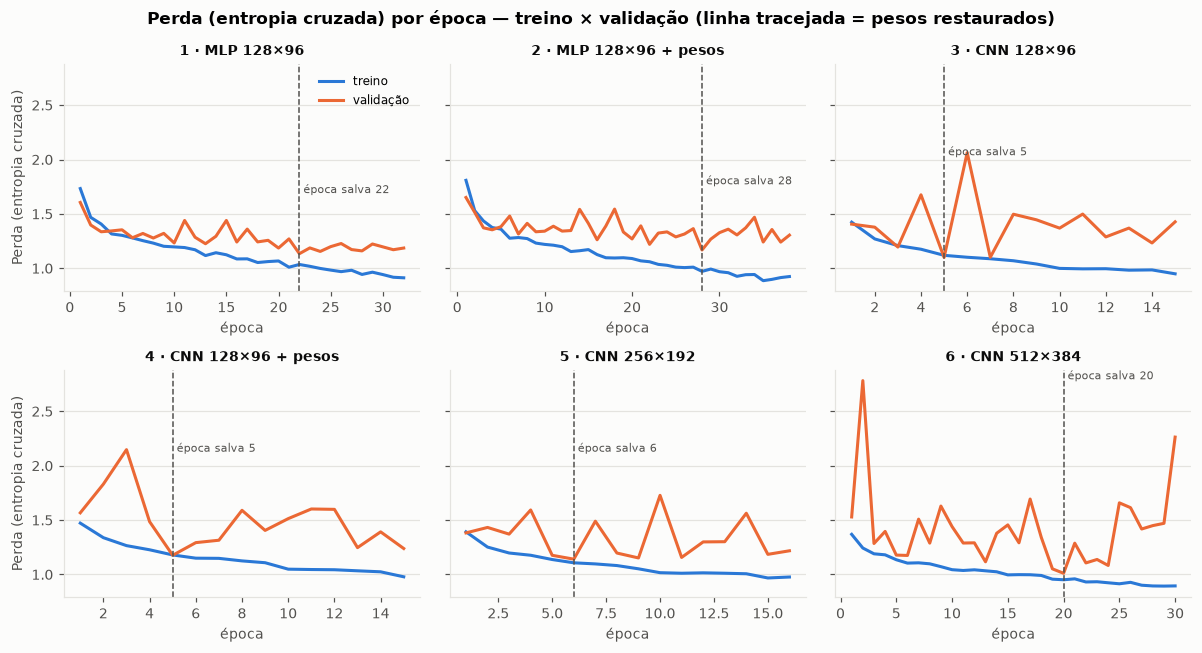

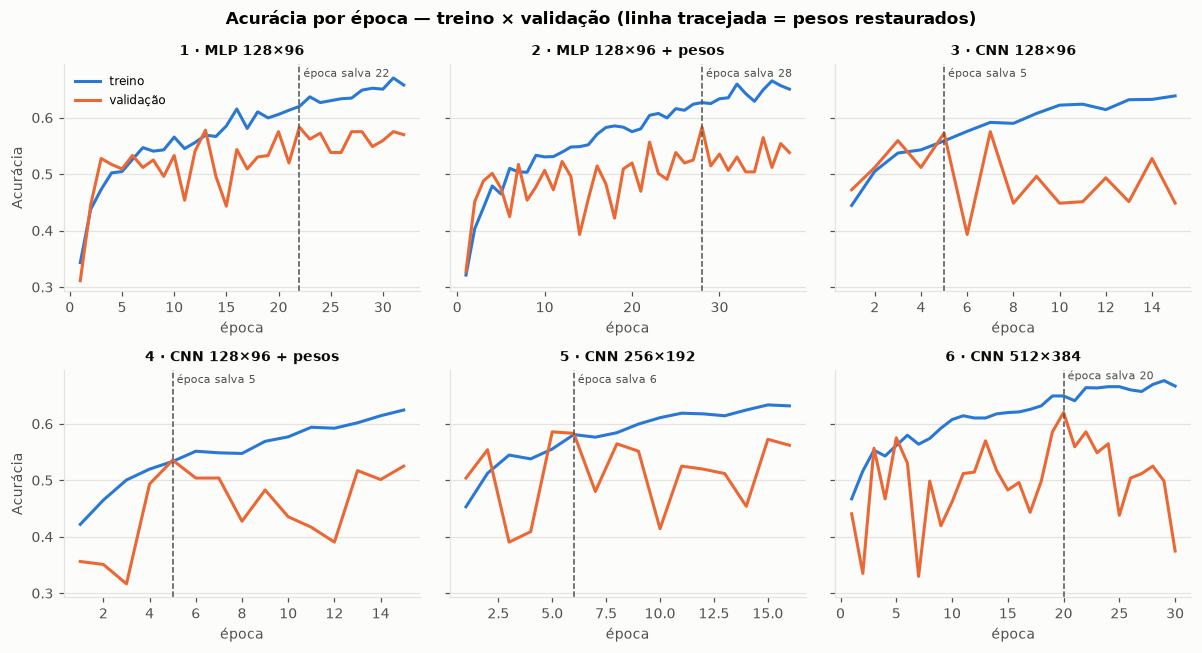

In [6]:
def curvas(chave, titulo, arquivo):
    fig, axs = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
    for ax, e in zip(axs.ravel(), EXPERIMENTOS):
        ax.set_title(NOMES[e], fontsize=9)
        if e not in R: ax.text(0.5, 0.5, "não executado", ha="center", transform=ax.transAxes); continue
        h = R[e]["history"]; ep = np.arange(1, len(h[chave]) + 1)
        ax.plot(ep, h[chave], color=AZUL, lw=2, label="treino")
        ax.plot(ep, h["val_" + chave], color=LARANJA, lw=2, label="validação")
        ax.axvline(h["melhor_epoca"], color=TEXTO_2, lw=1, ls="--")
        ax.text(h["melhor_epoca"], ax.get_ylim()[1], f" época salva {h['melhor_epoca']}", fontsize=7, color=TEXTO_2, va="top")
        ax.set_xlabel("época")
    axs[0, 0].set_ylabel(titulo); axs[1, 0].set_ylabel(titulo)
    axs[0, 0].legend(loc="best", fontsize=8)
    fig.suptitle(f"{titulo} por época — treino × validação (linha tracejada = pesos restaurados)", fontweight="bold")
    plt.tight_layout(); salvar(fig, arquivo); plt.show()

curvas("loss", "Perda (entropia cruzada)", "res_01_curvas_perda.png")
curvas("accuracy", "Acurácia", "res_02_curvas_acuracia.png")

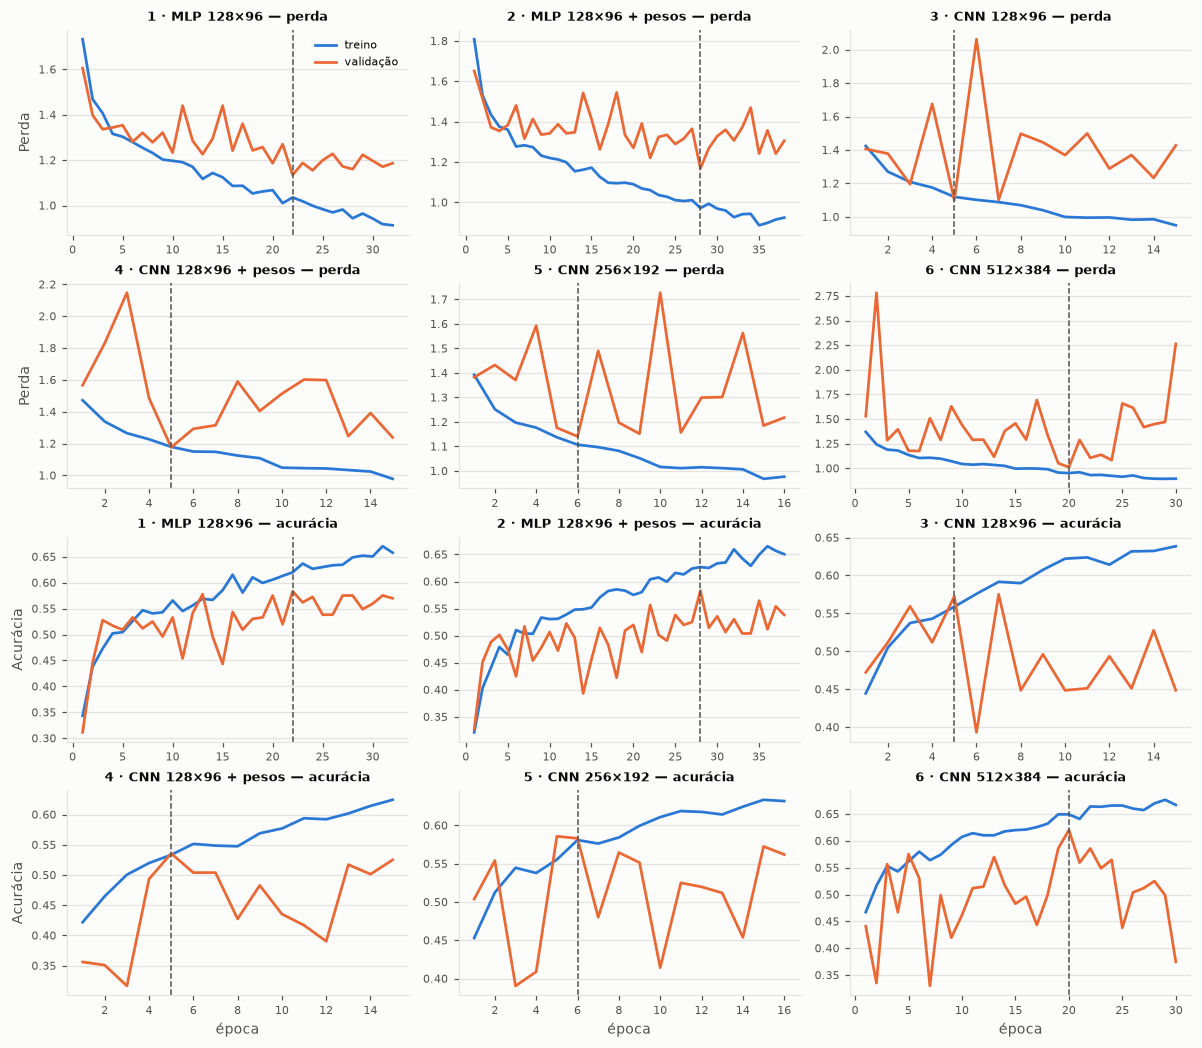

In [7]:
# Versao compacta para o artigo: perda (2 linhas de cima) e acuracia (2 linhas de baixo)
fig, axs = plt.subplots(4, 3, figsize=(11, 9.6))
for k, (chave, rotulo) in enumerate([("loss", "Perda"), ("accuracy", "Acurácia")]):
    for ax, e in zip(axs[2 * k:2 * k + 2].ravel(), EXPERIMENTOS):
        h = R[e]["history"]; ep = np.arange(1, len(h[chave]) + 1)
        ax.plot(ep, h[chave], color=AZUL, lw=1.8, label="treino")
        ax.plot(ep, h["val_" + chave], color=LARANJA, lw=1.8, label="validação")
        ax.axvline(h["melhor_epoca"], color=TEXTO_2, lw=1, ls="--")
        ax.set_title(f"{NOMES[e]} — {rotulo.lower()}", fontsize=8.5)
        ax.tick_params(labelsize=7)
    axs[2 * k, 0].set_ylabel(rotulo); axs[2 * k + 1, 0].set_ylabel(rotulo)
for ax in axs[-1]: ax.set_xlabel("época")
axs[0, 0].legend(fontsize=7, loc="upper right")
plt.tight_layout(h_pad=0.6)
salvar(fig, "res_01b_curvas_perda_acuracia.png"); plt.show()

## 4. Matrizes de confusão (teste) — reais nas linhas, previstas nas colunas

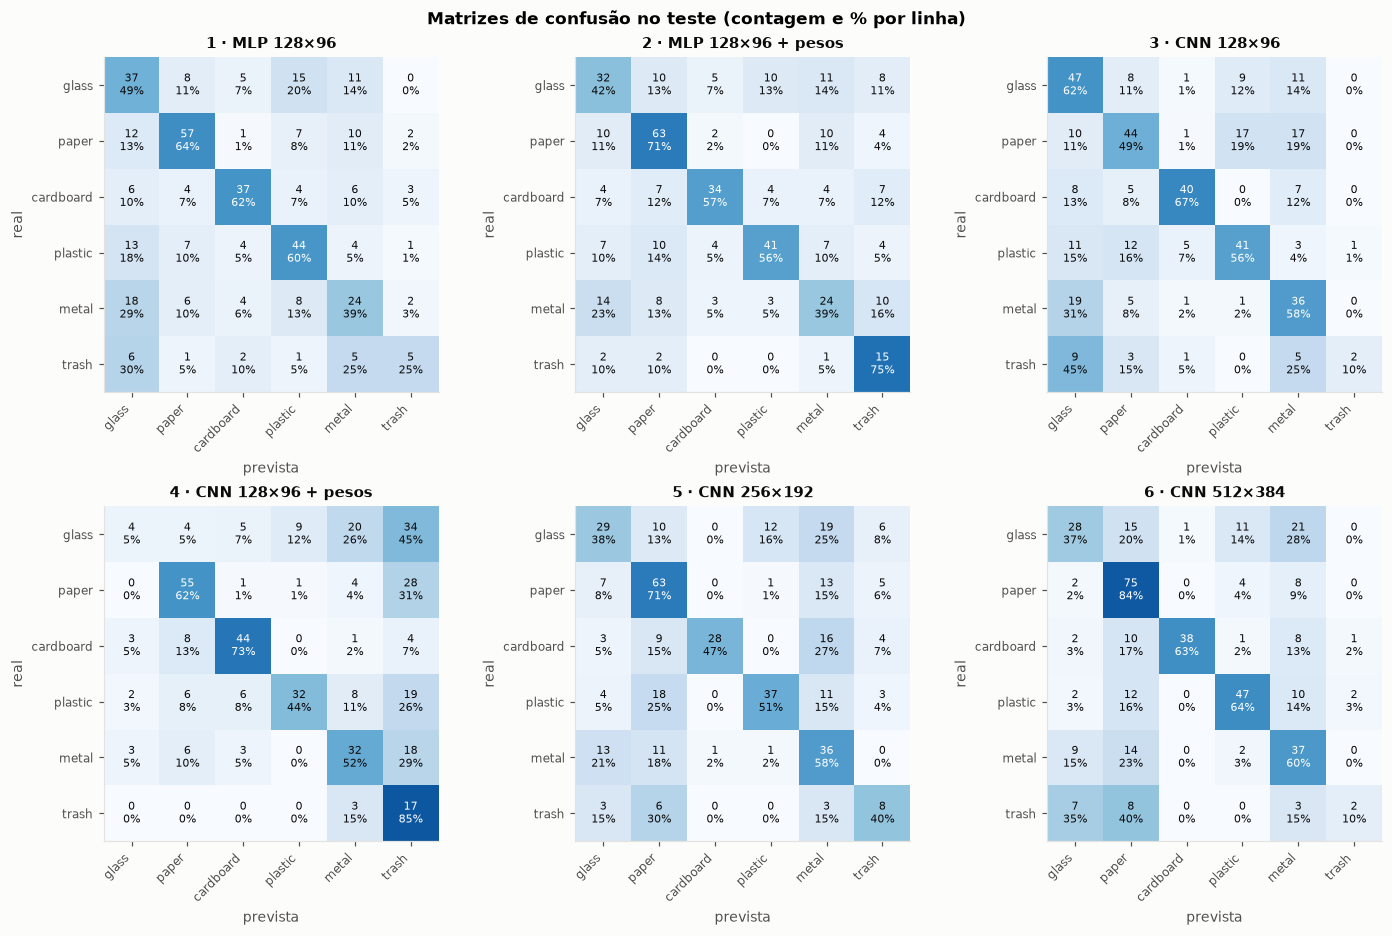

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(13, 8.6))
for ax, e in zip(axs.ravel(), EXPERIMENTOS):
    ax.set_title(NOMES[e], fontsize=10)
    if e not in R: ax.axis("off"); continue
    m = np.array(R[e]["metrics"]["teste"]["matriz_confusao"])
    pct = 100 * m / m.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{m[i, j]}\n{pct[i, j]:.0f}%", ha="center", va="center", fontsize=7,
                    color="white" if pct[i, j] > 55 else TEXTO)
    ax.set_xticks(range(6), CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(6), CLASSES, fontsize=8)
    ax.set_xlabel("prevista"); ax.set_ylabel("real"); ax.grid(False)
fig.suptitle("Matrizes de confusão no teste (contagem e % por linha)", fontweight="bold")
plt.tight_layout(); salvar(fig, "res_03_matrizes_confusao.png"); plt.show()

## 5. Efeito da resolução na CNN (sem pesos: experimentos 3, 5 e 6)

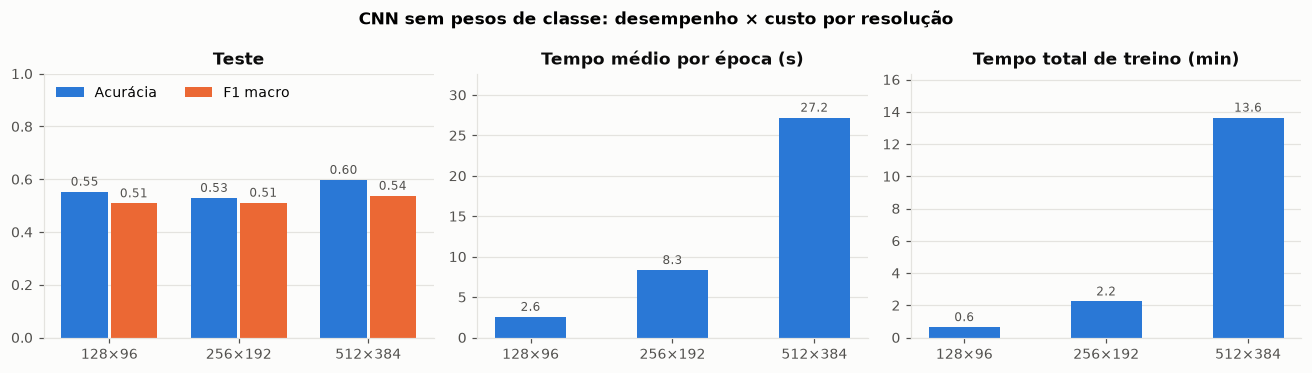

,acuracia_teste,f1_macro_teste,tempo_epoca_s,tempo_total_min,epocas,pico_vram_mb
128×96,0.553,0.509,2.557,0.644,15,466.109
256×192,0.529,0.511,8.341,2.237,16,1409.294
512×384,0.597,0.537,27.190,13.634,30,5168.469


In [9]:
res_exps = [e for e in ["exp3_cnn_128x96", "exp5_cnn_256x192", "exp6_cnn_512x384"] if e in R]
rot = [f"{EXPERIMENTOS[e]['resolucao'][0]}×{EXPERIMENTOS[e]['resolucao'][1]}" for e in res_exps]
acc = [R[e]["metrics"]["teste"]["acuracia"] for e in res_exps]
f1 = [R[e]["metrics"]["teste"]["f1_macro"] for e in res_exps]
t_ep = [R[e]["cost"]["tempo_medio_epoca_s"] for e in res_exps]
t_tot = [R[e]["cost"]["tempo_total_s"] / 60 for e in res_exps]
x = np.arange(len(res_exps))

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for k, (vals, nome, cor) in enumerate([(acc, "Acurácia", AZUL), (f1, "F1 macro", LARANJA)]):
    b = axs[0].bar(x + (k - 0.5) * 0.38, vals, 0.36, color=cor, label=nome)
    axs[0].bar_label(b, fmt="%.2f", fontsize=8, padding=2, color=TEXTO_2)
axs[0].set_xticks(x, rot); axs[0].set_ylim(0, 1); axs[0].set_title("Teste"); axs[0].legend(ncols=2, loc="upper left")
for ax, vals, tit, fmt in [(axs[1], t_ep, "Tempo médio por época (s)", "%.1f"), (axs[2], t_tot, "Tempo total de treino (min)", "%.1f")]:
    b = ax.bar(x, vals, 0.5, color=AZUL); ax.bar_label(b, fmt=fmt, fontsize=8, padding=2, color=TEXTO_2)
    ax.set_xticks(x, rot); ax.set_title(tit); ax.set_ylim(0, max(vals) * 1.2)
fig.suptitle("CNN sem pesos de classe: desempenho × custo por resolução", fontweight="bold")
plt.tight_layout(); salvar(fig, "res_04_resolucao.png"); plt.show()

pd.DataFrame({"acuracia_teste": acc, "f1_macro_teste": f1, "tempo_epoca_s": t_ep, "tempo_total_min": t_tot,
              "epocas": [R[e]["cost"]["epocas_executadas"] for e in res_exps],
              "pico_vram_mb": [R[e]["cost"]["pico_vram_mb"] for e in res_exps]}, index=rot).round(3)

## 6. Efeito dos pesos de classe (por classe, teste)

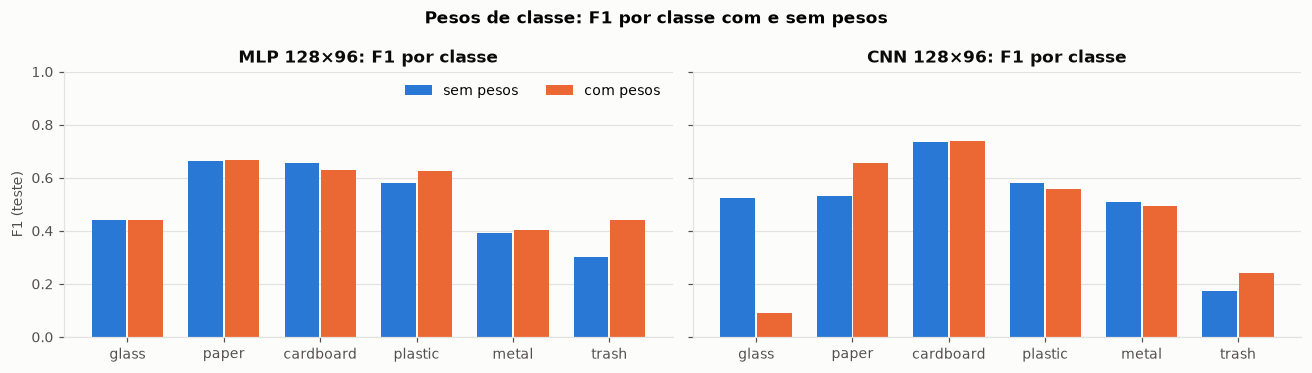

,modelo,classe,recall_sem,recall_com,f1_sem,f1_com,delta_f1
0,MLP 128×96,glass,0.49,0.42,0.44,0.44,0.00
1,MLP 128×96,paper,0.64,0.71,0.66,0.67,0.00
2,MLP 128×96,cardboard,0.62,0.57,0.65,0.63,-0.03
3,MLP 128×96,plastic,0.60,0.56,0.58,0.63,0.05
4,MLP 128×96,metal,0.39,0.39,0.39,0.40,0.01
5,MLP 128×96,trash,0.25,0.75,0.30,0.44,0.14
6,CNN 128×96,glass,0.62,0.05,0.52,0.09,-0.43
7,CNN 128×96,paper,0.49,0.62,0.53,0.65,0.12
8,CNN 128×96,cardboard,0.67,0.73,0.73,0.74,0.01
9,CNN 128×96,plastic,0.56,0.44,0.58,0.56,-0.03


In [10]:
pares = [("MLP 128×96", "exp1_mlp_128x96", "exp2_mlp_128x96_pesos"), ("CNN 128×96", "exp3_cnn_128x96", "exp4_cnn_128x96_pesos")]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
x = np.arange(len(CLASSES))
for ax, (tit, sem, com) in zip(axs, pares):
    if sem not in R or com not in R: ax.set_title(tit + " (incompleto)"); continue
    for k, (e, nome, cor) in enumerate([(sem, "sem pesos", AZUL), (com, "com pesos", LARANJA)]):
        pc = R[e]["metrics"]["teste"]["por_classe"]
        ax.bar(x + (k - 0.5) * 0.38, [pc[c]["f1-score"] for c in CLASSES], 0.36, color=cor, label=nome)
    ax.set_xticks(x, CLASSES); ax.set_title(f"{tit}: F1 por classe"); ax.set_ylim(0, 1)
axs[0].legend(ncols=2, loc="upper right"); axs[0].set_ylabel("F1 (teste)")
fig.suptitle("Pesos de classe: F1 por classe com e sem pesos", fontweight="bold")
plt.tight_layout(); salvar(fig, "res_05_pesos_por_classe.png"); plt.show()

dif = []
for tit, sem, com in pares:
    if sem in R and com in R:
        for c in CLASSES:
            a, b = R[sem]["metrics"]["teste"]["por_classe"][c], R[com]["metrics"]["teste"]["por_classe"][c]
            dif.append({"modelo": tit, "classe": c, "recall_sem": a["recall"], "recall_com": b["recall"],
                        "f1_sem": a["f1-score"], "f1_com": b["f1-score"], "delta_f1": b["f1-score"] - a["f1-score"]})
dif = pd.DataFrame(dif); dif.round(3).to_csv(TAB_DIR / "tabela_efeito_pesos.csv", index=False)
dif.round(2)

## 7. Análise de erros do modelo selecionado (maior F1 macro de validação)

In [11]:
print("Modelo:", NOMES[melhor_exp], "| F1 macro val =", round(R[melhor_exp]["metrics"]["validacao"]["f1_macro"], 3))
prev = R[melhor_exp]["predictions"]
erros = prev[~prev["acertou"]].sort_values("prob_prevista", ascending=False)
print(f"Erros no teste: {len(erros)} de {len(prev)}")
print("Confusões mais frequentes (real -> prevista):")
print(erros.groupby(["real", "prevista"]).size().sort_values(ascending=False).head(8).to_string())

Modelo: 2 · MLP 128×96 + pesos | F1 macro val = 0.56
Erros no teste: 171 de 380
Confusões mais frequentes (real -> prevista):
real     prevista
metal    glass       14
glass    metal       11
         paper       10
paper    glass       10
         metal       10
metal    trash       10
plastic  paper       10
glass    plastic     10


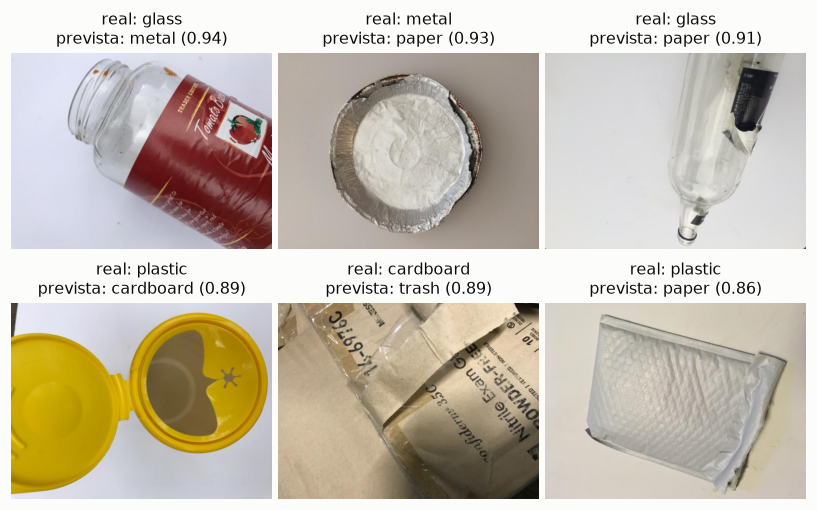

,caminho,real,prevista,prob_prevista
44,glass/glass340.jpg,glass,metal,0.940
311,metal/metal169.jpg,metal,paper,0.927
37,glass/glass275.jpg,glass,paper,0.913
280,plastic/plastic436.jpg,plastic,cardboard,0.888
198,cardboard/cardboard302.jpg,cardboard,trash,0.887
283,plastic/plastic455.jpg,plastic,paper,0.864


In [12]:
# Até 6 erros: os mais confiantes, no máximo 2 por classe real, para variar os casos
escolha = erros.groupby("real").head(2).head(6)
DADOS = encontrar_raiz(DATA_DIR)
fig, axs = plt.subplots(2, 3, figsize=(7.5, 5.0))
for ax, (_, r) in zip(axs.ravel(), escolha.iterrows()):
    ax.imshow(Image.open(DADOS / r["caminho"])); ax.axis("off")
    ax.set_title(f"real: {r['real']}\nprevista: {r['prevista']} ({r['prob_prevista']:.2f})", fontsize=10.5, fontweight="normal")
for ax in axs.ravel()[len(escolha):]: ax.axis("off")
plt.tight_layout(h_pad=0.4, w_pad=0.4)
salvar(fig, "res_06_erros.png"); plt.show()
escolha[["caminho", "real", "prevista", "prob_prevista"]]